In [ ]:
import pandas as pd

# 1. Load the dataset
df = pd.read_parquet('/content/drive/MyDrive/MABSA_Shared_Project/data/master_dataset.parquet')
print("Shape:", df.shape)

# 2. Check missing values
print("\n--- Missing values per column ---")
print(df.isnull().sum())

print("\n--- Empty string check ---")
for col in ['domain', 'language', 'split', 'sentence', 'aspect', 'category', 'sentiment']:
    empty_count = (df[col].astype(str).str.strip() == '').sum()
    print(f"{col}: {empty_count} empty strings")

# 3. Identify the mismatch (aspect empty but is_null_aspect=False)
mismatch = df[(df['aspect'].isnull() | (df['aspect'].astype(str).str.strip() == ''))
              & (df['is_null_aspect'] == False)]
print(f"\nRows with mismatch before fix: {len(mismatch)}")

# 4. Apply the fix — flip is_null_aspect to True for these rows
df.loc[(df['aspect'].astype(str).str.strip() == '') & (df['is_null_aspect'] == False), 'is_null_aspect'] = True

# 5. Drop the 1 empty-sentence row
df = df[df['sentence'].astype(str).str.strip() != '']

# 6. Re-check to confirm both fixes worked
mismatch_after = df[(df['aspect'].isnull() | (df['aspect'].astype(str).str.strip() == ''))
                     & (df['is_null_aspect'] == False)]
print(f"Rows with mismatch after fix: {len(mismatch_after)}")
print("New shape:", df.shape)

# 7. Save the cleaned dataset back to Drive (this makes the fix permanent)
df.to_parquet('/content/drive/MyDrive/MABSA_Shared_Project/data/master_dataset.parquet', index=False)
print("Saved cleaned dataset to Drive.")

Shape: (438342, 8)

--- Missing values per column ---
domain            0
language          0
split             0
sentence          0
aspect            0
category          0
sentiment         0
is_null_aspect    0
dtype: int64

--- Empty string check ---
domain: 0 empty strings
language: 0 empty strings
split: 0 empty strings
sentence: 1 empty strings
aspect: 412 empty strings
category: 0 empty strings
sentiment: 0 empty strings

Rows with mismatch before fix: 412
Rows with mismatch after fix: 0
New shape: (438341, 8)
Saved cleaned dataset to Drive.


**Cramér's V association matrix**

Initially asked for label encoding + Pearson correlation — flagged as statistically inappropriate for categorical data

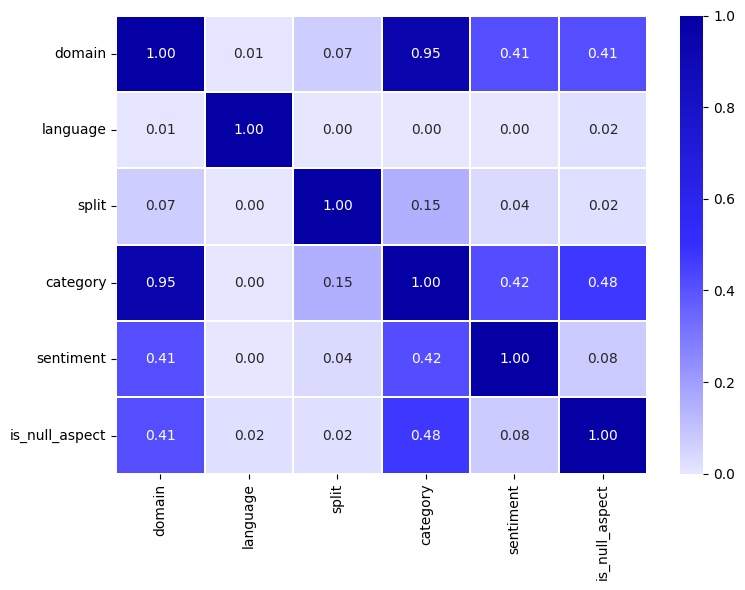

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
from itertools import combinations

custom_cmap = LinearSegmentedColormap.from_list(
    'custom', ['#E6E6FF', '#352EFF', '#0500A3']
)

def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    phi2 = chi2 / n
    phi2corr = max(0, phi2 - ((k-1)*(r-1)) / (n-1))
    rcorr = r - ((r-1)**2) / (n-1)
    kcorr = k - ((k-1)**2) / (n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

cols = ['domain', 'language', 'split', 'category', 'sentiment', 'is_null_aspect']

corr_matrix = pd.DataFrame(np.ones((len(cols), len(cols))), index=cols, columns=cols)

for col1, col2 in combinations(cols, 2):
    v = cramers_v(df[col1].astype(str), df[col2].astype(str))
    corr_matrix.loc[col1, col2] = v
    corr_matrix.loc[col2, col1] = v

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap=custom_cmap, vmin=0, vmax=1, fmt='.2f',
            linewidths=0.3, linecolor='white')
plt.tight_layout()
plt.savefig('/content/correlation_heatmap.pdf', dpi=300)
plt.show()

group
sentence          0.508589
category          0.250349
domain            0.136443
aspect            0.033294
language          0.032742
split             0.031905
is_null_aspect    0.006679
Name: importance, dtype: float64


/tmp/ipykernel_3972/718822129.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=grouped_importance.values, y=grouped_importance.index, palette='viridis')


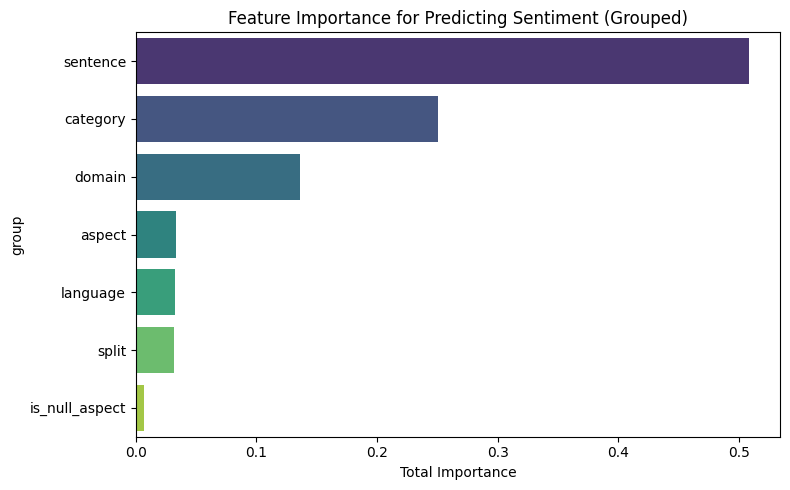

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Target
y = df['sentiment']

# --- One-hot encode proper categorical features ---
cat_cols = ['domain', 'language', 'split', 'category', 'is_null_aspect']
X_cat = pd.get_dummies(df[cat_cols].astype(str), prefix=cat_cols)

# --- TF-IDF for text features (limit vocab so it stays manageable) ---
tfidf_sentence = TfidfVectorizer(max_features=300, stop_words='english')
X_sentence = tfidf_sentence.fit_transform(df['sentence'].astype(str))
sentence_feature_names = [f"sentence_{w}" for w in tfidf_sentence.get_feature_names_out()]

tfidf_aspect = TfidfVectorizer(max_features=100)
X_aspect = tfidf_aspect.fit_transform(df['aspect'].astype(str))
aspect_feature_names = [f"aspect_{w}" for w in tfidf_aspect.get_feature_names_out()]

# --- Combine everything into one sparse matrix ---
X_combined = hstack([csr_matrix(X_cat.values), X_sentence, X_aspect])
all_feature_names = list(X_cat.columns) + sentence_feature_names + aspect_feature_names

# --- Train Random Forest ---
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_combined, y)

# --- Aggregate importance back to original feature groups ---
raw_importance = pd.DataFrame({
    'feature': all_feature_names,
    'importance': rf.feature_importances_
})

def group_feature(f):
    if f.startswith('sentence_'):
        return 'sentence'
    if f.startswith('aspect_'):
        return 'aspect'
    for col in cat_cols:
        if f.startswith(col + '_'):
            return col
    return f

raw_importance['group'] = raw_importance['feature'].apply(group_feature)
grouped_importance = raw_importance.groupby('group')['importance'].sum().sort_values(ascending=False)

print(grouped_importance)

plt.figure(figsize=(8, 5))
sns.barplot(x=grouped_importance.values, y=grouped_importance.index, palette='viridis')
plt.title('Feature Importance for Predicting Sentiment (Grouped)')
plt.xlabel('Total Importance')
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

df = pd.read_parquet("/content/drive/MyDrive/MABSA_Shared_Project/data/master_dataset.parquet")

# Category counts per domain
cat_by_domain = df.groupby("domain")["category"].value_counts()
print(cat_by_domain)

# Full unique category list (needed for TASD label map)
unique_categories = sorted(df["category"].dropna().unique())
print(f"Total unique categories: {len(unique_categories)}")
print(unique_categories)

# Restaurant-only (what Phase 3 needs immediately)
restaurant_categories = sorted(df[df.domain == "restaurant"]["category"].dropna().unique())
print(f"Restaurant categories: {len(restaurant_categories)}")
print(restaurant_categories)

domain    category               
coursera  course general             19188
          faculty general             5660
          course quality              4311
          presentation quality        2780
          assignments quality         2474
                                     ...  
sight     Instructor                 14108
          Course_General_Feedback    11356
          Other                       8313
          Teaching_Setup              3211
          NULL                           1
Name: count, Length: 290, dtype: int64
Total unique categories: 283
['After-sales Service#Exchange/Warranty/Return', 'Appearance Design#Aesthetics General', 'Appearance Design#Color', 'Appearance Design#Exterior Design Material', 'Appearance Design#Fuselage Size', 'Appearance Design#Grip Feeling', 'Appearance Design#Thickness', 'Appearance Design#Weight', 'Appearance Design#Workmanship and Texture', 'Audio/Sound#Tone quality', 'Audio/Sound#Volume and Speaker', 'BATTERY#DESIGN_FEATURES', '

In [ ]:
import pandas as pd

df = pd.read_parquet("/content/drive/MyDrive/MABSA_Shared_Project/data/master_dataset.parquet")

# --- Step 1: Confirm NaN rows are implicit-sentiment (no explicit category) ---
n_null_category = df["category"].isna().sum()
print(f"Rows with NaN category (implicit sentiment, expected): {n_null_category}")
print(f"Total rows: {len(df)}")

# Don't drop these — just make sure downstream .unique()/value_counts() calls
# use dropna() (or dropna=True, the pandas default) so NaN doesn't get treated
# as a fake category. Confirm nothing already turned NaN into a literal string:
print("\nLiteral 'NULL'/'nan'/'None' strings hiding in category column:")
print(df["category"].astype(str).str.strip().str.lower().isin(["null", "nan", "none", ""]).sum())

# --- Step 2: Check for whitespace/case inconsistencies BEFORE normalizing ---
raw_categories = df["category"].dropna().unique()
normalized_categories = df["category"].dropna().str.strip().str.lower().unique()

print(f"\nRaw unique categories: {len(raw_categories)}")
print(f"Normalized unique categories: {len(normalized_categories)}")
print(f"Collapsed by normalization: {len(raw_categories) - len(normalized_categories)}")

# --- Step 3: Show exactly which raw labels collapse into the same normalized label ---
# This tells you what was inconsistent (e.g., "Food General" vs "food general ")
norm_map = (
    df["category"].dropna()
    .to_frame()
    .assign(norm=lambda x: x["category"].str.strip().str.lower())
    .groupby("norm")["category"]
    .unique()
)

collapsed = norm_map[norm_map.apply(len) > 1]
print(f"\nNormalized labels with multiple raw variants ({len(collapsed)}):")
for norm_label, variants in collapsed.items():
    print(f"  {norm_label!r} <- {list(variants)}")

Rows with NaN category (implicit sentiment, expected): 0
Total rows: 438341

Literal 'NULL'/'nan'/'None' strings hiding in category column:
1

Raw unique categories: 283
Normalized unique categories: 283
Collapsed by normalization: 0

Normalized labels with multiple raw variants (0):


In [ ]:
mask = df["category"].astype(str).str.strip().str.upper() == "NULL"
df.loc[mask, "category"] = pd.NA

df.to_parquet("/content/drive/MyDrive/MABSA_Shared_Project/data/master_dataset_clean.parquet", index=False)

In [ ]:
dupes_within = df.groupby(["split", "domain", "language"])["sentence"].apply(
    lambda x: x.duplicated().sum()
)
print(dupes_within[dupes_within > 0])

train_sents = set(df[df.split == "train"]["sentence"])
test_sents = set(df[df.split == "test"]["sentence"])
leak = train_sents & test_sents
print(f"Sentences appearing in both train and test: {len(leak)}")

split  domain    language
dev    coursera  ar          108
                 da          110
                 de          109
                 en          110
                 es          108
                            ... 
train  sight     sw          533
                 th          533
                 tr          532
                 vi          533
                 zh          533
Name: sentence, Length: 441, dtype: int64
Sentences appearing in both train and test: 554
